# M0: Setup, data and network construction

**Project:** Reproducing and extending *"Analysis and Resilience of the U.S. Flight Network"* (Pandey & Kafle, arXiv:2505.11559)
**Paper section covered:** 2 (Dataset, Data Filtering, Network Construction)

## Goal
Build the U.S. Flight Network (USFN) exactly as the paper does, and make every filtering step visible, so that all later milestones start from a network we fully understand.

## What the paper says it did
1. Keep airports whose `Country == United States`.
2. Keep routes where **both** source and destination are in that list (domestic only).
3. Count how often each (source, destination) pair occurs and use it as the **edge weight**, which also removes direction (undirected graph).
4. Nodes are airports (IATA code); result is a weighted undirected graph, reported as 541 nodes and 2,780 edges.

## What this notebook does
- Documents the data (a data card).
- Walks through the filtering step by step with counts.
- Explains the one thing the paper does not say: the reported 541 nodes is the **largest connected component**.
- Builds the final graph and sanity-checks it, draws it on a map.
- Ends with assertions that compare our network with the paper's numbers.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

print("networkx", nx.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("project root:", ROOT)

networkx 3.4.2 | pandas 2.2.1 | numpy 1.26.2
project root: /Users/k.mokshithareddy/Desktop/Sem 9/ns


## 2. Data card

| Item | Detail |
|---|---|
| Source | **OpenFlights** open database (`airports.dat`, `routes.dat`, `airlines.dat`, `planes.dat`) |
| Relation to the paper | The paper uses the Kaggle *Global Air Transportation Network* dataset (Tyler Woebkenberg), which is a repackaging of OpenFlights. Its `airports.csv` has 7,658 airports; our OpenFlights copy has 7,698, so the world files differ slightly. As shown below, the **US network we build is identical to the paper's**. |
| Route data age | OpenFlights' data page states that its third-party route source stopped providing updates in **June 2014**; the file is a historical snapshot (67,663 routes, exactly the size of our file). The paper never states this. |
| Codeshare caveat | OpenFlights notes that its route counts do not separate operated from codeshared flights, which can double-count. We quantify this in section 5. |
| Files used here | `airports.dat` (airport metadata) and `routes.dat` (one row per airline per directed airport pair) |
| Not used here | `airlines.dat`, `planes.dat` (airline names and aircraft types; useful later for the multilayer-by-airline extension) |
| Missing values | OpenFlights marks missing values with `\N`; we read these as `NaN` |

Both `.dat` files have no header row, so column names come from the OpenFlights documentation.

In [2]:
airports, routes = usfn.load_openflights()

print(f"airports.dat : {len(airports):>7,} rows x {airports.shape[1]} columns")
print(f"routes.dat   : {len(routes):>7,} rows x {routes.shape[1]} columns")
display(airports.head(3))
display(routes.head(3))

airports.dat :   7,698 rows x 14 columns
routes.dat   :  67,663 rows x 9 columns


,id,name,city,country,iata,icao,lat,lon,alt,tz,dst,tzdb,type,source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.08169,145.391998,5282,10.0,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.20708,145.789001,20,10.0,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.82679,144.296005,5388,10.0,U,Pacific/Port_Moresby,airport,OurAirports


,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equip
0,2B,410.0,AER,2965.0,KZN,2990.0,NaN,0,CR2
1,2B,410.0,ASF,2966.0,KZN,2990.0,NaN,0,CR2
2,2B,410.0,ASF,2966.0,MRV,2962.0,NaN,0,CR2


**Route columns:** `airline` (IATA code), `src` / `dst` (IATA codes of origin and destination), `codeshare` (`Y` if the flight is operated by another airline), `stops` (0 = direct), `equip` (aircraft types).
Important: **one row is one airline operating one directed airport pair**, not one flight and not one passenger.

## 3. Step-by-step filtering

We rebuild the paper's pipeline one step at a time and count what survives each step.

In [3]:
# Step A: US airports
us_all  = airports[airports.country == "United States"]
us_iata = us_all.dropna(subset=["iata"])                 # routes refer to airports by IATA code
dup_iata = int(us_iata.iata.duplicated().sum())
us_codes = set(us_iata.iata)

# Step B: domestic routes (both ends are US airports)
src_us  = routes[routes.src.isin(us_codes)]
dom     = routes[routes.src.isin(us_codes) & routes.dst.isin(us_codes)]
n_loops = int((dom.src == dom.dst).sum())
dom_ok  = dom[dom.src != dom.dst]

# Step C: collapse to undirected airport pairs; weight = number of route rows
pairs = dom_ok.assign(a=dom_ok[["src", "dst"]].min(axis=1), b=dom_ok[["src", "dst"]].max(axis=1))
undirected_pairs = pairs.groupby(["a", "b"]).size()
nodes_all = set(pairs.a) | set(pairs.b)

# Step D: largest connected component (what the paper actually analyses)
G_all = usfn.build_country_network(airports, routes, largest_component=False)
G     = usfn.build_country_network(airports, routes, largest_component=True)

funnel = pd.DataFrame([
    ("Airports in file (world)",                           len(airports)),
    ("  ... with country == United States",                len(us_all)),
    ("  ... that also have an IATA code",                  len(us_iata)),
    ("  ... duplicate IATA codes among them",              dup_iata),
    ("Route rows in file (world)",                         len(routes)),
    ("  ... whose source is a US airport",                 len(src_us)),
    ("  ... whose source AND destination are US (domestic)", len(dom)),
    ("  ... of which self-loops (src == dst)",             n_loops),
    ("Distinct undirected airport pairs  = EDGES (before LCC)", len(undirected_pairs)),
    ("Distinct airports in those pairs   = NODES (before LCC)", len(nodes_all)),
    ("After keeping largest connected component: NODES",   G.number_of_nodes()),
    ("After keeping largest connected component: EDGES",   G.number_of_edges()),
], columns=["step", "count"])
funnel["count"] = funnel["count"].map("{:,}".format)
funnel.style.hide(axis="index").set_properties(subset=["step"], **{"text-align": "left"})

step,count
Airports in file (world),"7,698"
... with country == United States,"1,512"
... that also have an IATA code,"1,251"
... duplicate IATA codes among them,0
Route rows in file (world),"67,663"
... whose source is a US airport,"13,100"
... whose source AND destination are US (domestic),"10,518"
... of which self-loops (src == dst),0
Distinct undirected airport pairs = EDGES (before LCC),"2,787"
Distinct airports in those pairs = NODES (before LCC),549


**Reading the funnel.** Of about 7,700 airports worldwide, ~1,250 are US airports with an IATA code, but only 549 of them appear in any domestic route in the data (the rest have no scheduled domestic service recorded). Roughly 10,500 domestic route rows collapse into ~2,790 distinct airport pairs.

## 4. The 541 vs 549 question

The paper reports 541 nodes but never mentions that this is a *subset*. Before taking the largest connected component, the domestic graph has 549 airports. The extra 8 form tiny pieces that are disconnected from the main network, so path lengths and diameter (which need a connected graph) would be undefined. Here they are:

In [4]:
comps = sorted(nx.connected_components(G_all), key=len, reverse=True)
print("Number of connected components:", len(comps))
print("Component sizes               :", [len(c) for c in comps])

rows = []
for ci, comp in enumerate(comps[1:], start=1):
    for n in sorted(comp):
        rows.append({"component": ci, "iata": n, "name": G_all.nodes[n]["name"],
                     "city": G_all.nodes[n]["city"], "degree": G_all.degree(n),
                     "linked_to": ", ".join(sorted(G_all.neighbors(n)))})
dropped = pd.DataFrame(rows)
dropped

Number of connected components: 3
Component sizes               : [541, 4, 4]


,component,iata,name,city,degree,linked_to
0,1,AKB,Atka Airport,Atka,1,DUT
1,1,DUT,Unalaska Airport,Unalaska,3,"AKB, IKO, KQA"
2,1,IKO,Nikolski Air Station,Nikolski,1,DUT
3,1,KQA,Akutan Seaplane Base,Akutan,1,DUT
4,2,BFI,Boeing Field King County International Airport,Seattle,3,"CLM, ESD, FRD"
5,2,CLM,William R Fairchild International Airport,Port Angeles,1,BFI
6,2,ESD,Orcas Island Airport,Eastsound,2,"BFI, FRD"
7,2,FRD,Friday Harbor Airport,Friday Harbor,2,"BFI, ESD"


There are two isolated clusters of four airports each: an Aleutian/Alaska group around Unalaska (DUT) and a Puget Sound group around Seattle's Boeing Field (BFI). Neither has a route to the main network in this data. Dropping them is the only way the paper's numbers (541 nodes, finite diameter 7) can come out, so **we follow the same convention**: every later milestone uses the 541-node largest connected component, and we call this graph `G`.

## 5. What the edge weight actually means

The paper calls the weight "the number of flights". In OpenFlights it is really the **number of route rows** between two airports, i.e. the number of (airline, direction) combinations listed for that pair, **including codeshare listings**. It is not passengers, and not flights per day. Let us inspect it.

In [5]:
w = pd.Series({(u, v): d["weight"] for u, v, d in G.edges(data=True)})

print("Sum of all edge weights   :", int(w.sum()), "(domestic route rows inside the 541-node LCC)")
print("Domestic rows, no loops   :", len(dom_ok), "(all 549 nodes; the 8 dropped airports hold the other rows)")
print(f"Weight range              : {w.min()} to {w.max()}   | mean {w.mean():.2f} | median {w.median():.0f}")
print(f"Edges with weight 1       : {(w == 1).mean():.1%}")
print(f"Edges with weight 2       : {(w == 2).mean():.1%}")

# why are weights mostly even/multiples? each airline normally appears once per direction
ex = dom_ok[((dom_ok.src == "ATL") & (dom_ok.dst == "ORD")) | ((dom_ok.src == "ORD") & (dom_ok.dst == "ATL"))]
print(f"\nExample ATL-ORD: weight = {G['ATL']['ORD']['weight']}  (rows below: airline x direction)")
display(ex[["airline", "src", "dst", "codeshare", "stops", "equip"]].sort_values(["airline", "src"]).head(12))

n_dirs = pairs.drop_duplicates(["src", "dst"]).groupby(["a", "b"]).size()
both_dir = (n_dirs == 2).mean()
print(f"\nShare of airport pairs served in BOTH directions: {both_dir:.1%}")
print(f"Share of domestic route rows marked codeshare = Y : {(dom_ok.codeshare == 'Y').mean():.1%}")

Sum of all edge weights   : 10507 (domestic route rows inside the 541-node LCC)
Domestic rows, no loops   : 10518 (all 549 nodes; the 8 dropped airports hold the other rows)
Weight range              : 1 to 39   | mean 3.78 | median 3
Edges with weight 1       : 3.6%
Edges with weight 2       : 44.8%

Example ATL-ORD: weight = 39  (rows below: airline x direction)


,airline,src,dst,codeshare,stops,equip
4702,AA,ATL,ORD,Y,0,CR7 E75
6230,AA,ORD,ATL,Y,0,E75 CR7
9128,AF,ATL,ORD,Y,0,757 319 320 M88 M90
9834,AF,ORD,ATL,Y,0,717 M88
13021,AZ,ATL,ORD,Y,0,757 717 M88
13591,AZ,ORD,ATL,Y,0,M88
14420,BA,ATL,ORD,Y,0,E75 CR7
14854,BA,ORD,ATL,Y,0,E75 CR7 74N
17818,CX,ATL,ORD,Y,0,E75
17993,CX,ORD,ATL,Y,0,CR7



Share of airport pairs served in BOTH directions: 95.6%
Share of domestic route rows marked codeshare = Y : 44.0%


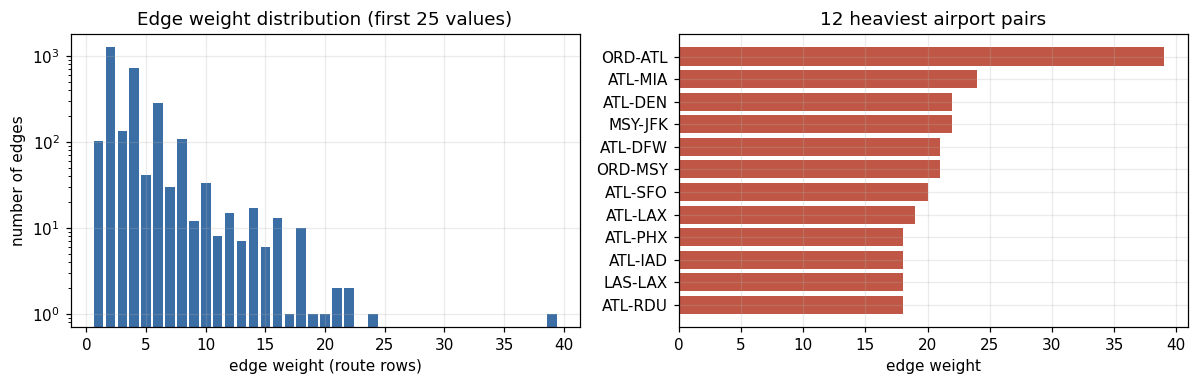

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
vc = w.value_counts().sort_index()
axes[0].bar(vc.index[:25], vc.values[:25], color="#3b6ea5")
axes[0].set_yscale("log"); axes[0].set_xlabel("edge weight (route rows)"); axes[0].set_ylabel("number of edges")
axes[0].set_title("Edge weight distribution (first 25 values)")

top = w.sort_values(ascending=False).head(12)
labels = [f"{a}-{b}" for a, b in top.index]
axes[1].barh(labels[::-1], top.values[::-1], color="#c05746")
axes[1].set_xlabel("edge weight"); axes[1].set_title("12 heaviest airport pairs")
plt.tight_layout(); plt.show()

**Reading this.** Weights are small integers: the median is 3, and nearly half of all edges (44.8%) have weight 2, which is one airline serving a pair in both directions. Few edges have weight 1 because almost every pair is served both ways (95.6%). The heaviest pairs are mostly hub-to-hub (ATL-ORD, ATL-MIA, ATL-DEN) but also include pairs such as MSY-JFK, a hint that **codeshare listings inflate the weight**: for ATL-ORD, many of the airlines in the table (AA, AF, AZ, BA, CX) are marked codeshare `Y`, not operators. Let us measure how much.

In [7]:
operated = dom_ok[dom_ok.codeshare != "Y"]             # rows marked as the operating carrier's own flight
p2 = operated.assign(a=operated[["src", "dst"]].min(axis=1), b=operated[["src", "dst"]].max(axis=1))
w_op = p2.groupby(["a", "b"]).size()
w_s = pd.Series({tuple(sorted((u, v))): d["weight"] for u, v, d in G.edges(data=True)})   # same keys as w_op

common = w_s.index.intersection(w_op.index)
from scipy.stats import spearmanr
rho = spearmanr(w_s.loc[common], w_op.loc[common]).statistic

lost_edges = [e for e in w_s.index if e not in w_op.index]
print(f"Edges if we keep only non-codeshare rows : {len(w_op):,} (vs {len(w_s):,} in G)  -> {len(lost_edges)} edges of G exist only through codeshare listings")
print(f"Rank correlation of weight vs operated-only weight (Spearman, shared edges) : {rho:.2f}")
print(f"Median weight  all rows: {w_s.median():.0f}   |   operated only: {w_op.median():.0f}")

cmp_ = pd.DataFrame({"all_rows": w_s, "operated_only": w_op}).fillna(0).astype(int)
cmp_.loc[[("ATL", "ORD"), ("ATL", "MIA"), ("JFK", "MSY"), ("ATL", "DEN")]]

Edges if we keep only non-codeshare rows : 2,072 (vs 2,780 in G)  -> 715 edges of G exist only through codeshare listings
Rank correlation of weight vs operated-only weight (Spearman, shared edges) : 0.66
Median weight  all rows: 3   |   operated only: 2


all_rows  operated_only
ATL ORD        39              2
    MIA        24              4
JFK MSY        22              4
ATL DEN        22              8

**Take-away:** the paper's weight mixes operating service with codeshare marketing listings. The two are only moderately rank-correlated (Spearman about 0.66), and **715 of the 2,780 edges (26%) have no non-codeshare row at all** in this data. For those pairs either the operating carrier's row is missing from OpenFlights or the pair is marketing-only; the file cannot tell us which. ATL-ORD is the extreme case: weight 39 with all rows, but only 2 operated rows. This does not change the reproduction, but it is a real data-quality caveat on the paper. We keep the paper's definition of the graph for faithful reproduction, but **M7 (weighted analysis)** will compare it with an operated-flights-only weighting, and **M8** replaces both with real flight counts from the BTS file. Note also that the paper builds the weights but never uses them.

## 6. The final network

We now confirm that the library function `usfn.build_country_network` (used by every later notebook) gives the same graph as the manual walk-through above.

In [8]:
# manual rebuild from the funnel step, to cross-check the library function
H = nx.Graph()
for (a, b), cnt in undirected_pairs.items():
    H.add_edge(a, b, weight=int(cnt))
H = H.subgraph(max(nx.connected_components(H), key=len)).copy()

same_nodes = set(H.nodes) == set(G.nodes)
same_edges = {frozenset(e) for e in H.edges} == {frozenset(e) for e in G.edges}
same_w = all(H[u][v]["weight"] == G[u][v]["weight"] for u, v in H.edges)
print("manual graph == library graph  ->  nodes:", same_nodes, "| edges:", same_edges, "| weights:", same_w)

print("\nGraph type      :", type(G).__name__, "(undirected)")
print("Connected       :", nx.is_connected(G))
print("Self-loops      :", nx.number_of_selfloops(G))
print("Node attributes :", sorted(next(iter(G.nodes(data=True)))[1].keys()))
print("Edge attributes :", sorted(next(iter(G.edges(data=True)))[2].keys()))

manual graph == library graph  ->  nodes: True | edges: True | weights: True

Graph type      : Graph (undirected)
Connected       : True
Self-loops      : 0
Node attributes : ['city', 'lat', 'lon', 'name']
Edge attributes : ['weight']


In [9]:
deg = pd.Series(dict(G.degree()), name="degree")
strength = pd.Series(dict(G.degree(weight="weight")), name="strength (sum of weights)")
top10 = pd.concat([deg, strength], axis=1).sort_values("degree", ascending=False).head(10)
top10.insert(0, "name", [G.nodes[n]["name"] for n in top10.index])
top10.insert(1, "city", [G.nodes[n]["city"] for n in top10.index])
top10

,name,city,degree,strength (sum of weights)
ATL,Hartsfield Jackson Atlanta International Airport,Atlanta,153,1496
ORD,Chicago O'Hare International Airport,Chicago,149,752
DEN,Denver International Airport,Denver,149,653
DFW,Dallas Fort Worth International Airport,Dallas-Fort Worth,138,657
MSP,Minneapolis-St Paul International/Wold-Chamber...,Minneapolis,117,380
DTW,Detroit Metropolitan Wayne County Airport,Detroit,114,340
LAS,McCarran International Airport,Las Vegas,113,404
CLT,Charlotte Douglas International Airport,Charlotte,110,477
IAH,George Bush Intercontinental Houston Airport,Houston,101,287
PHL,Philadelphia International Airport,Philadelphia,88,412


## 7. The network on a map

Nodes are placed at their real latitude and longitude. Node size grows with degree. The left panel shows all 541 airports (Alaska and Hawaii stretch the frame); the right panel zooms on the contiguous 48 states.

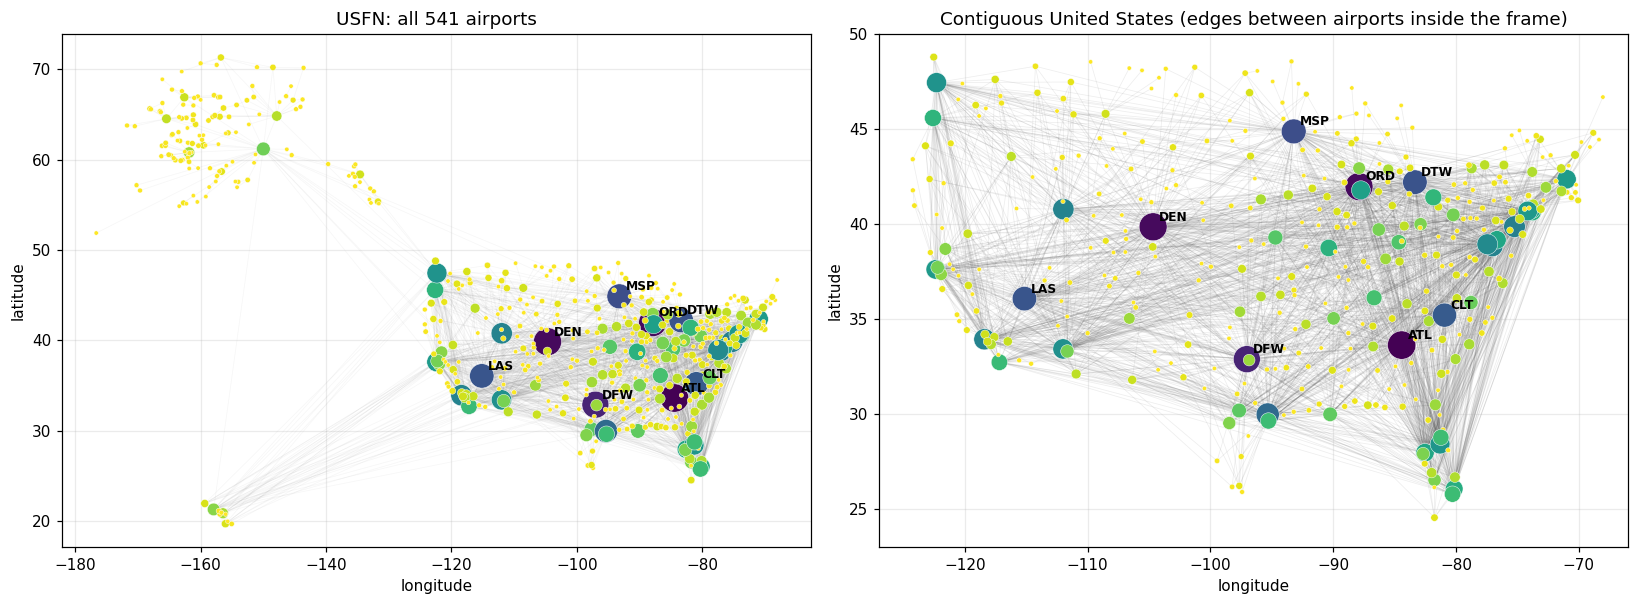

In [10]:
def draw(ax, G, extent=None, edge_alpha=0.12, node_scale=6):
    pos = {n: (d["lon"], d["lat"]) for n, d in G.nodes(data=True)}
    for u, v in G.edges():
        (x1, y1), (x2, y2) = pos[u], pos[v]
        if extent and not (extent[0] <= x1 <= extent[1] and extent[2] <= y1 <= extent[3] and
                           extent[0] <= x2 <= extent[1] and extent[2] <= y2 <= extent[3]):
            continue
        ax.plot([x1, x2], [y1, y2], color="#555", alpha=edge_alpha, lw=0.5, zorder=1)
    xs = [pos[n][0] for n in G]; ys = [pos[n][1] for n in G]
    sizes = [node_scale + 2.2 * G.degree(n) for n in G]
    ax.scatter(xs, ys, s=sizes, c=[G.degree(n) for n in G], cmap="viridis_r",
               edgecolor="white", linewidth=0.3, zorder=2)
    for n, _ in sorted(G.degree, key=lambda x: -x[1])[:8]:
        if extent is None or (extent[0] <= pos[n][0] <= extent[1] and extent[2] <= pos[n][1] <= extent[3]):
            ax.annotate(n, pos[n], fontsize=8, weight="bold", xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    if extent: ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
draw(axes[0], G, edge_alpha=0.05)
axes[0].set_title("USFN: all 541 airports")
draw(axes[1], G, extent=(-127, -66, 23, 50), edge_alpha=0.10)
axes[1].set_title("Contiguous United States (edges between airports inside the frame)")
plt.tight_layout(); plt.show()

The two clusters outside the lower-48 frame are **Alaska** (top left) and **Hawaii** (bottom left). Notice how Alaska is a dense cloud of small airports with few lines to the mainland. That is why Anchorage (ANC) later turns out to be the top betweenness airport (**M1**).

## 8. Check against the paper

Everything the paper states about the network's size and hub, compared with what we built.

In [11]:
from math import isclose

paper = {"nodes": 541, "edges": 2780, "max_degree_airport": "ATL", "max_degree": 153}
max_node, max_deg = max(G.degree, key=lambda x: x[1])

check = pd.DataFrame([
    ("Number of nodes",         paper["nodes"],              G.number_of_nodes()),
    ("Number of edges",         paper["edges"],              G.number_of_edges()),
    ("Highest-degree airport",  paper["max_degree_airport"], max_node),
    ("Highest degree",          paper["max_degree"],         max_deg),
    ("Graph is connected",      True,                        nx.is_connected(G)),
    ("Weighted & undirected",   True,                        (not G.is_directed()) and all("weight" in d for *_, d in G.edges(data=True))),
], columns=["quantity", "paper", "ours"])
check["match"] = check.apply(lambda r: "OK" if r.paper == r.ours else "DIFF", axis=1)
display(check)

assert G.number_of_nodes() == 541
assert G.number_of_edges() == 2780
assert (max_node, max_deg) == ("ATL", 153)
assert nx.is_connected(G) and not G.is_directed() and nx.number_of_selfloops(G) == 0
assert all(isinstance(d["weight"], int) and d["weight"] >= 1 for *_, d in G.edges(data=True))
assert G_all.number_of_nodes() == 549 and G_all.number_of_edges() == 2787
assert same_nodes and same_edges and same_w
assert int(sum(d["weight"] for *_, d in G_all.edges(data=True))) == len(dom_ok)
print("All M0 assertions passed.")

,quantity,paper,ours,match
0,Number of nodes,541,541,OK
1,Number of edges,2780,2780,OK
2,Highest-degree airport,ATL,ATL,OK
3,Highest degree,153,153,OK
4,Graph is connected,True,True,OK
5,Weighted & undirected,True,True,OK


All M0 assertions passed.


## 9. Summary and take-aways

- We reproduce the paper's network **exactly**: 541 airports, 2,780 weighted undirected edges, ATL as the largest hub with degree 153.
- The paper's 541 is the **largest connected component** of a 549-node domestic graph; 8 isolated airports are dropped. This is undocumented in the paper and is now documented here.
- The "flight count" weight is really the number of OpenFlights route rows (airline x direction), and 44% of the domestic rows are codeshare listings, so it is a coarse, partly inflated proxy for service intensity (median 3). A quarter of the paper's edges (715 of 2,780) have no non-codeshare row at all in this data, a data-quality caveat that **M7** will test directly by repeating key results on an operated-only network.
- The data is an OpenFlights snapshot whose route information stopped updating in June 2014. Any conclusion is about that network, not today's.
- Nothing in the paper depends on edge weights, which we will exploit in **M7** (including an operated-only weighting) and replace with real flight counts in **M8**.

**Next:** M1 reproduces Section 3 (average path length, diameter, degree distribution, betweenness) on this exact graph.